# Backpropagation through time with NumPy

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/sequential-models/04-backpropagation-through-time.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

This notebook uses a deliberately small recurrent neural network (RNN) to make **backpropagation through time (BPTT)** visible. It has a two-dimensional hidden state and a shared $2\times2$ recurrent matrix. Rather than using an engineering dataset, we construct a delayed-cue task: the input appears at the beginning of a sequence, but the model is evaluated only at the end.

## What you will do

1. Build a synthetic delayed-cue sequence.
2. Run a two-state RNN forward through that sequence.
3. Implement the vector--matrix BPTT calculation with NumPy.
4. Verify the shared-matrix gradient using a finite-difference check.
5. Compare vanishing, balanced, and exploding-gradient settings.
6. See how a `tanh` activation changes the gradient path.
7. Optionally verify the same matrix gradient with PyTorch autograd.

## 1. A delayed-cue task

The sequence begins with a single cue, $x_1=1$, followed by zeros. The RNN sees one scalar input at a time, carries a two-entry hidden-state vector, and makes one final scalar prediction:

$$
 x_1 = 1,\qquad x_2=\cdots=x_T=0,\qquad
 h_0=\begin{bmatrix}0\\0\end{bmatrix},\qquad
 \widehat y=w_o^Th_T,\qquad y=1.
$$

The task is deliberately simple: useful information appears only at the first step, so the network must preserve it until the final time step.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")

INPUT_VECTOR = np.array([0.35, 0.15])
OUTPUT_VECTOR = np.array([1.0, 0.0])
TARGET = 1.0
ROTATION_ANGLE = np.deg2rad(10.0)
BASE_ROTATION = np.array([
    [np.cos(ROTATION_ANGLE), -np.sin(ROTATION_ANGLE)],
    [np.sin(ROTATION_ANGLE), np.cos(ROTATION_ANGLE)],
])


In [2]:
def make_delayed_cue_sequence(*, length: int) -> np.ndarray:
    """Create a sequence with one early cue and later zero inputs.

    Args:
        length: Number of time steps in the sequence.

    Returns:
        A one-dimensional array with a one at the first time step and zeros
        at all remaining time steps.
    """
    inputs = np.zeros(length, dtype=float)
    inputs[0] = 1.0
    return inputs


sequence = make_delayed_cue_sequence(length=16)
print(sequence)


[1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## 2. A two-state RNN and its forward pass

At every time step, the **same** matrix $W_h\in\mathbb{R}^{2\times2}$ is reused:

$$
\begin{aligned}
 a_t &= W_hh_{t-1}+w_xx_t, & a_t,h_t,w_x&\in\mathbb{R}^2,\\
 h_t &= \phi(a_t), & W_h&\in\mathbb{R}^{2\times2},\\
 \widehat y &= w_o^Th_T, & w_o&\in\mathbb{R}^2,\\
 L &= \tfrac12(\widehat y-y)^2.
\end{aligned}
$$

To make one control enough for this example, define $W_h=\alpha R$, where $R$ is a fixed $10^\circ$ rotation. Because $R$ preserves the length of a vector, $|\alpha|$ controls the repeated scale in the linear recurrence.

In [3]:
from typing import Literal

ActivationName = Literal["linear", "tanh"]


def recurrent_matrix(*, scale: float) -> np.ndarray:
    """Create the shared recurrent matrix W_h = alpha R.

    Args:
        scale: Scalar alpha multiplying the fixed rotation matrix R.

    Returns:
        A 2-by-2 recurrent matrix.
    """
    return scale * BASE_ROTATION


def apply_activation(*, values: np.ndarray, name: ActivationName) -> np.ndarray:
    """Apply an RNN activation elementwise to a two-entry vector.

    Args:
        values: Vector of pre-activation values.
        name: Either ``"linear"`` or ``"tanh"``.

    Returns:
        Activated vector with the same shape as ``values``.
    """
    if name == "linear":
        return values.copy()
    return np.tanh(values)


def activation_derivative(*, hidden_state: np.ndarray, name: ActivationName) -> np.ndarray:
    """Evaluate the elementwise activation derivative at one hidden state.

    Args:
        hidden_state: Activated hidden-state vector.
        name: Either ``"linear"`` or ``"tanh"``.

    Returns:
        A two-entry vector of activation derivatives.
    """
    if name == "linear":
        return np.ones_like(hidden_state)
    return 1.0 - hidden_state**2


def forward_two_state_rnn(
    *,
    inputs: np.ndarray,
    scale: float,
    activation: ActivationName,
) -> dict[str, np.ndarray | float]:
    """Run a two-state RNN forward through one sequence.

    Args:
        inputs: One-dimensional scalar input sequence with shape ``(T,)``.
        scale: Alpha in the recurrent matrix ``W_h = alpha R``.
        activation: Hidden-state activation applied elementwise.

    Returns:
        A dictionary with the recurrent matrix, pre-activations, hidden states
        including ``h_0``, activation derivatives, prediction, and loss.
    """
    length = len(inputs)
    matrix = recurrent_matrix(scale=scale)
    # Store the two-entry pre-activation a_t and hidden state h_t at every
    # time step.  The leading zero row makes states[0] the specified h_0=[0, 0].
    scores = np.zeros((length, 2), dtype=float)
    states = np.zeros((length + 1, 2), dtype=float)
    derivatives = np.zeros((length, 2), dtype=float)

    for time in range(1, length + 1):
        # The same 2-by-2 matrix is reused at every time step.
        scores[time - 1] = matrix @ states[time - 1] + INPUT_VECTOR * inputs[time - 1]
        # Apply the activation separately to each of the two state entries.
        states[time] = apply_activation(values=scores[time - 1], name=activation)
        derivatives[time - 1] = activation_derivative(hidden_state=states[time], name=activation)

    prediction = float(OUTPUT_VECTOR @ states[-1])
    loss = 0.5 * (prediction - TARGET) ** 2
    return {
        "inputs": inputs,
        "matrix": matrix,
        "scores": scores,
        "states": states,
        "derivatives": derivatives,
        "prediction": prediction,
        "loss": loss,
    }


trace = forward_two_state_rnn(inputs=sequence, scale=0.70, activation="linear")
print("Base rotation R:\n", BASE_ROTATION)
print("\nRecurrent matrix W_h = 0.70 R:\n", trace["matrix"])
print(f"\nPrediction: {trace['prediction']:.5f}")
print(f"Loss:       {trace['loss']:.5f}")


Base rotation R:
 [[ 0.98480775 -0.17364818]
 [ 0.17364818  0.98480775]]

Recurrent matrix W_h = 0.70 R:
 [[ 0.68936543 -0.12155372]
 [ 0.12155372  0.68936543]]

Prediction: -0.00180
Loss:       0.50180


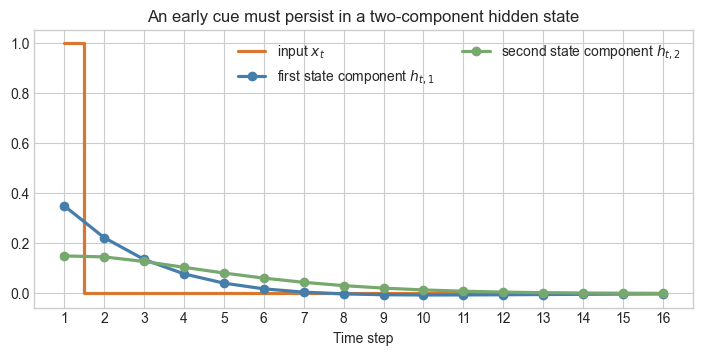

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
time = np.arange(1, len(sequence) + 1)
ax.step(time, sequence, where="mid", color="#d77732", linewidth=2.3, label=r"input $x_t$")
ax.plot(time, trace["states"][1:, 0], "o-", color="#457eaa", linewidth=2.3, label=r"first state component $h_{t,1}$")
ax.plot(time, trace["states"][1:, 1], "o-", color="#77a86d", linewidth=2.3, label=r"second state component $h_{t,2}$")
ax.set(xlabel="Time step", title="An early cue must persist in a two-component hidden state")
ax.set_xticks(time)
ax.legend(frameon=False, ncol=2, loc="upper right")
plt.show()


## 3. Backpropagate through the unrolled sequence

When the RNN is unrolled, each time step becomes a copy of the recurrent cell. All copies share the same $W_h$, so their separate $2\times2$ gradient contributions must be **summed**.

Define the backward vectors

$$
 g_t=\frac{\partial L}{\partial h_t}\in\mathbb{R}^2,
 \qquad
 \delta_t=\frac{\partial L}{\partial a_t}\in\mathbb{R}^2.
$$

Starting at the loss, BPTT is

$$
\begin{aligned}
 g_T &= (\widehat y-y)w_o,\\
 \delta_t &= g_t\odot\phi'(a_t),\\
 g_{t-1} &= W_h^T\delta_t,\\
 \frac{\partial L}{\partial W_h}
 &= \sum_{t=1}^{T}\delta_t h_{t-1}^T.
\end{aligned}
$$

The last line is a sum of outer products. Each time step supplies one $2\times2$ contribution to the single shared matrix.

In [5]:
def bptt_matrix_gradient(
    *,
    forward_trace: dict[str, np.ndarray | float],
) -> dict[str, np.ndarray | float]:
    """Compute the shared 2-by-2 recurrent-matrix gradient by BPTT.

    Args:
        forward_trace: Dictionary returned by ``forward_two_state_rnn``.

    Returns:
        A dictionary containing hidden-state gradients, pre-activation
        gradients, each 2-by-2 outer-product contribution, the total matrix
        gradient, and the gradient with respect to alpha.
    """
    matrix = np.asarray(forward_trace["matrix"])
    states = np.asarray(forward_trace["states"])
    derivatives = np.asarray(forward_trace["derivatives"])
    prediction = float(forward_trace["prediction"])
    length = len(derivatives)

    # gradient_hidden[t] is dL/dh_t.  delta[t-1] is dL/da_t, after the
    # activation derivative has been applied.
    gradient_hidden = np.zeros((length + 1, 2), dtype=float)
    delta = np.zeros((length, 2), dtype=float)
    # W_h is shared over time, so each unrolled step contributes one 2-by-2
    # outer product; BPTT adds all of those contributions.
    contributions = np.zeros((length, 2, 2), dtype=float)
    gradient_matrix = np.zeros((2, 2), dtype=float)

    # Start at the final loss, then move backward through time.
    gradient_hidden[-1] = (prediction - TARGET) * OUTPUT_VECTOR
    for time in range(length, 0, -1):
        index = time - 1
        # This multiplication is elementwise because the activation acts
        # elementwise on the two state entries.
        delta[index] = gradient_hidden[time] * derivatives[index]
        # dL/dW_h from this one time step is an outer product.
        contributions[index] = np.outer(delta[index], states[time - 1])
        gradient_matrix += contributions[index]
        gradient_hidden[time - 1] += matrix.T @ delta[index]

    return {
        "gradient_hidden": gradient_hidden,
        "delta": delta,
        "contributions": contributions,
        "gradient_matrix": gradient_matrix,
        "gradient_scale": float(np.sum(gradient_matrix * BASE_ROTATION)),
    }


backward_trace = bptt_matrix_gradient(forward_trace=trace)
print("dL/dW_h:\n", backward_trace["gradient_matrix"])
print(f"\ndL/dalpha = {backward_trace['gradient_scale']:.8f}")


dL/dW_h:
 [[ 0.01515227 -0.00707618]
 [ 0.00414162  0.02199957]]

dL/dalpha = 0.03853538


In [6]:
def loss_at_scale(
    *,
    inputs: np.ndarray,
    scale: float,
    activation: ActivationName,
) -> float:
    """Evaluate the final RNN loss at one recurrent-matrix scale.

    Args:
        inputs: Input sequence.
        scale: Alpha in ``W_h = alpha R``.
        activation: Hidden-state activation.

    Returns:
        The scalar final-time loss.
    """
    trace = forward_two_state_rnn(inputs=inputs, scale=scale, activation=activation)
    return float(trace["loss"])


def finite_difference_scale_gradient(
    *,
    inputs: np.ndarray,
    scale: float,
    activation: ActivationName,
    epsilon: float = 1e-6,
) -> float:
    """Approximate dL/dalpha with a symmetric finite difference.

    Args:
        inputs: Input sequence.
        scale: Alpha about which the loss is perturbed.
        activation: Hidden-state activation.
        epsilon: Small perturbation size.

    Returns:
        A numerical approximation of the gradient with respect to alpha.
    """
    loss_plus = loss_at_scale(inputs=inputs, scale=scale + epsilon, activation=activation)
    loss_minus = loss_at_scale(inputs=inputs, scale=scale - epsilon, activation=activation)
    return (loss_plus - loss_minus) / (2.0 * epsilon)


analytic_gradient = float(backward_trace["gradient_scale"])
numerical_gradient = finite_difference_scale_gradient(
    inputs=sequence,
    scale=0.70,
    activation="linear",
)
print(f"BPTT dL/dalpha:              {analytic_gradient:.8f}")
print(f"Finite-difference dL/dalpha: {numerical_gradient:.8f}")
print(f"Absolute difference:          {abs(analytic_gradient - numerical_gradient):.2e}")


BPTT dL/dalpha:              0.03853538
Finite-difference dL/dalpha: 0.03853538
Absolute difference:          6.01e-12


## 4. Why gradients vanish or explode

For the linear cell, BPTT propagates a vector backward as

$$
 g_{t-1}=W_h^Tg_t=\alpha R^Tg_t.
$$

Because $R$ is a rotation, it does not change a vector's length. Thus the gradient norm is multiplied by $|\alpha|$ at every step in this particular construction. The comparison below changes only $\alpha$.

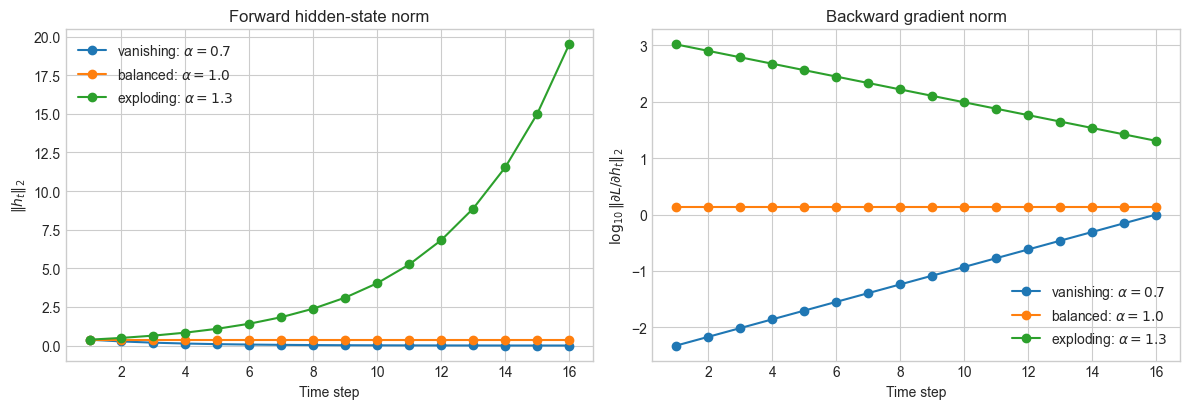

In [7]:
settings = {
    "vanishing": 0.70,
    "balanced": 1.00,
    "exploding": 1.30,
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for label, scale in settings.items():
    case_trace = forward_two_state_rnn(inputs=sequence, scale=scale, activation="linear")
    case_backward = bptt_matrix_gradient(forward_trace=case_trace)
    time = np.arange(1, len(sequence) + 1)
    axes[0].plot(time, np.linalg.norm(case_trace["states"][1:], axis=1), "o-", label=fr"{label}: $\alpha={scale:.1f}$")
    axes[1].plot(
        time,
        np.log10(np.maximum(np.linalg.norm(case_backward["gradient_hidden"][1:], axis=1), 1e-12)),
        "o-",
        label=fr"{label}: $\alpha={scale:.1f}$",
    )

axes[0].set(title="Forward hidden-state norm", xlabel="Time step", ylabel=r"$\|h_t\|_2$")
axes[1].set(title="Backward gradient norm", xlabel="Time step", ylabel=r"$\log_{10}\|\partial L/\partial h_t\|_2$")
for axis in axes:
    axis.legend(frameon=False)
plt.tight_layout()
plt.show()


In [8]:
rows = []
for label, scale in settings.items():
    case_trace = forward_two_state_rnn(inputs=sequence, scale=scale, activation="linear")
    case_backward = bptt_matrix_gradient(forward_trace=case_trace)
    terminal_norm = np.linalg.norm(case_backward["gradient_hidden"][-1])
    early_norm = np.linalg.norm(case_backward["gradient_hidden"][1])
    rows.append((
        label,
        scale,
        float(case_trace["loss"]),
        float(np.linalg.norm(case_backward["gradient_matrix"])),
        early_norm / max(terminal_norm, 1e-12),
    ))

print("setting      alpha     loss     ||dL/dW_h||_F   ||g_1||_2 / ||g_T||_2")
for label, scale, loss, gradient_norm, ratio in rows:
    print(f"{label:<10} {scale:>5.1f}  {loss:>9.4f}  {gradient_norm:>14.4f}  {ratio:>21.4e}")


setting      alpha     loss     ||dL/dW_h||_F   ||g_1||_2 / ||g_T||_2
vanishing    0.7     0.5018          0.0279             4.7476e-03
balanced     1.0     0.9496          5.6676             1.0000e+00
exploding    1.3   207.1394       3295.8784             5.1186e+01


The balanced case is not magically optimal: it merely makes the repeated linear transformation norm-preserving in this toy construction. In a practical RNN, the recurrent matrix, activation derivatives, and individual input sequence together determine whether gradients grow or shrink.

## 5. Add `tanh`: bounded states, another gradient factor

A conventional simple RNN often uses an elementwise `tanh` activation:

$$
 h_t=\tanh(a_t),\qquad \phi'(a_t)=1-h_t^2.
$$

The hidden-state vector is now bounded component by component between $-1$ and $1$. That can prevent the forward state from becoming arbitrarily large, but saturation also introduces small entries into the elementwise derivative vector. The backward path therefore has additional opportunities to vanish.

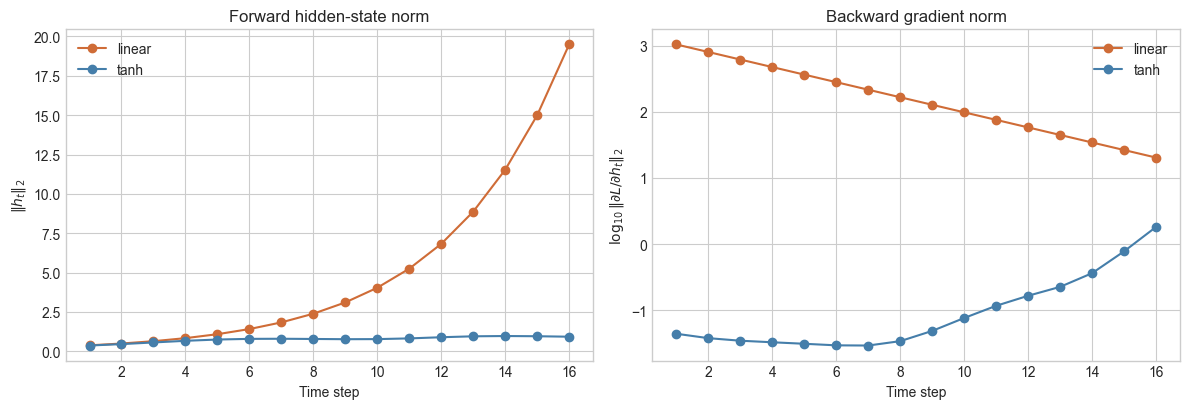

In [9]:
linear_trace = forward_two_state_rnn(inputs=sequence, scale=1.30, activation="linear")
linear_backward = bptt_matrix_gradient(forward_trace=linear_trace)

tanh_trace = forward_two_state_rnn(inputs=sequence, scale=1.30, activation="tanh")
tanh_backward = bptt_matrix_gradient(forward_trace=tanh_trace)

time = np.arange(1, len(sequence) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(time, np.linalg.norm(linear_trace["states"][1:], axis=1), "o-", color="#cf6c37", label="linear")
axes[0].plot(time, np.linalg.norm(tanh_trace["states"][1:], axis=1), "o-", color="#457eaa", label="tanh")
axes[0].set(title="Forward hidden-state norm", xlabel="Time step", ylabel=r"$\|h_t\|_2$")
axes[0].legend(frameon=False)

axes[1].plot(
    time,
    np.log10(np.maximum(np.linalg.norm(linear_backward["gradient_hidden"][1:], axis=1), 1e-12)),
    "o-",
    color="#cf6c37",
    label="linear",
)
axes[1].plot(
    time,
    np.log10(np.maximum(np.linalg.norm(tanh_backward["gradient_hidden"][1:], axis=1), 1e-12)),
    "o-",
    color="#457eaa",
    label="tanh",
)
axes[1].set(title="Backward gradient norm", xlabel="Time step", ylabel=r"$\log_{10}\|\partial L/\partial h_t\|_2$")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()


## 6. (Optional) Verify the matrix result with PyTorch autograd

In practice, frameworks build the unrolled computational graph and compute these derivatives automatically. The code below keeps the same $W_h=\alpha R$ structure and asks PyTorch for $dL/d\alpha$. It should match the manual BPTT result to numerical precision.

In [10]:
import torch

# requires_grad=True tells PyTorch to retain the operations involving alpha
# so that loss.backward() can later compute dL/dalpha.
scale = torch.tensor(0.70, dtype=torch.float64, requires_grad=True)
# These are fixed constants, so they do not require gradients.
rotation = torch.tensor(BASE_ROTATION, dtype=torch.float64)
input_vector = torch.tensor(INPUT_VECTOR, dtype=torch.float64)
output_vector = torch.tensor(OUTPUT_VECTOR, dtype=torch.float64)
inputs_torch = torch.tensor(sequence, dtype=torch.float64)
# Explicit h_0=[0, 0], matching the NumPy forward-pass example above.
hidden = torch.zeros(2, dtype=torch.float64)

for input_value in inputs_torch:
    # Reusing `scale` here creates one unrolled graph node per time step;
    # PyTorch will sum their gradient contributions during backward().
    hidden = (scale * rotation) @ hidden + input_vector * input_value

loss = 0.5 * (output_vector @ hidden - TARGET) ** 2
# Reverse-mode autodiff now traverses the entire unrolled graph backward.
loss.backward()

print(f"PyTorch autograd dL/dalpha: {scale.grad.item():.8f}")
print(f"Manual BPTT dL/dalpha:     {analytic_gradient:.8f}")


PyTorch autograd dL/dalpha: 0.03853538
Manual BPTT dL/dalpha:     0.03853538


## 7. Takeaway

BPTT is not a different calculus rule. It is the chain rule applied to an RNN after copying the recurrent cell across time. The key difference from an ordinary feed-forward network is that one recurrent matrix is reused at every time step, so its gradient is the sum of contributions from the unrolled copies. The backward path multiplies many local Jacobian matrices, which is the source of vanishing and exploding gradients. This motivates gated architectures such as LSTMs and GRUs.

[← Return to Sequential models](http://localhost:4170/sequential-models/)